In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("EMG Signal Detective — Day 1")
print("My first signal analysis project!")

EMG Signal Detective — Day 1
My first signal analysis project!


In [2]:
numbers = np.array([10, 20, 30, 40, 50])

average = np.mean(numbers)

print(average)

30.0


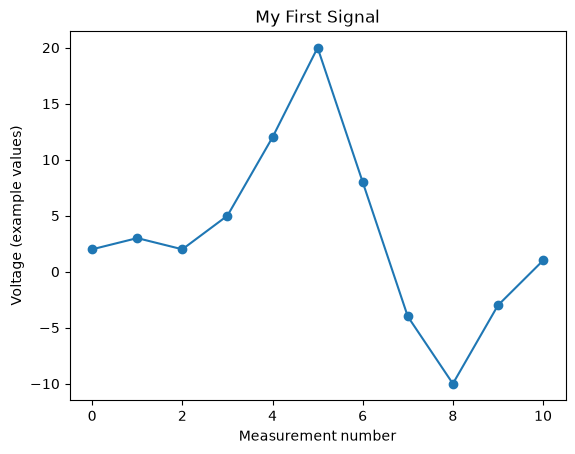

In [3]:
# Example voltage measurements (made-up data for practice)
voltage = np.array([2, 3, 2, 5, 12, 20, 8, -4, -10, -3, 1])

# The measurement number for each value
time = np.arange(len(voltage))

# Create the graph
plt.plot(time, voltage, marker="o")

plt.xlabel("Measurement number")
plt.ylabel("Voltage (example values)")
plt.title("My First Signal")

plt.show()

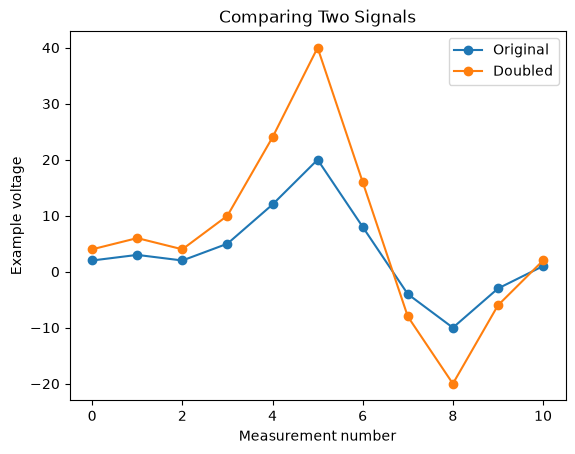

In [4]:
voltage = np.array([2, 3, 2, 5, 12, 20, 8, -4, -10, -3, 1])

# Make every measurement twice as large
stronger_signal = voltage * 2

plt.plot(time, voltage, marker="o", label="Original")
plt.plot(time, stronger_signal, marker="o", label="Doubled")

plt.xlabel("Measurement number")
plt.ylabel("Example voltage")
plt.title("Comparing Two Signals")
plt.legend()
plt.show()

In [5]:
%pip install wfdb

Note: you may need to restart the kernel to use updated packages.


In [6]:
import wfdb

print("WFDB is ready!")

WFDB is ready!


In [7]:
record = wfdb.rdrecord(
    "S01",
    pn_dir="semg/1.0.1",
    sampfrom=0,
    sampto=4000
)

print("Sampling rate:", record.fs, "samples/second")
print("Signal channels:", record.sig_name)
print("Data shape:", record.p_signal.shape)

Sampling rate: 2000 samples/second
Signal channels: ['baso LT FOOT', 'gonio RT HIP', 'semg LT TIB.A', 'semg LT LAT.G', 'semg LT REC.F', 'semg LT HAM', 'semg LT LAT.V', 'baso RT FOOT', 'gonio RT KNEE', 'semg RT TIB.A', 'semg RT LAT.G', 'semg RT REC.F', 'semg RT HAM', 'semg RT LAT.V']
Data shape: (4000, 14)


In [8]:
records = wfdb.get_record_list("semg/1.0.1")
print(records)

['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19', 'S20', 'S21', 'S22', 'S23', 'S24', 'S25', 'S26', 'S27', 'S28', 'S29', 'S30', 'S31']


In [9]:
record = wfdb.rdrecord(
    "S01",
    pn_dir="semg/1.0.1",
    sampfrom=0,
    sampto=4000
)

print(record.sig_name)

['baso LT FOOT', 'gonio RT HIP', 'semg LT TIB.A', 'semg LT LAT.G', 'semg LT REC.F', 'semg LT HAM', 'semg LT LAT.V', 'baso RT FOOT', 'gonio RT KNEE', 'semg RT TIB.A', 'semg RT LAT.G', 'semg RT REC.F', 'semg RT HAM', 'semg RT LAT.V']


In [10]:
emg = record.p_signal[:, 2]
print(emg.shape)

(4000,)


In [11]:
time = np.arange(len(emg)) / record.fs

print(time[:5])


[0.     0.0005 0.001  0.0015 0.002 ]


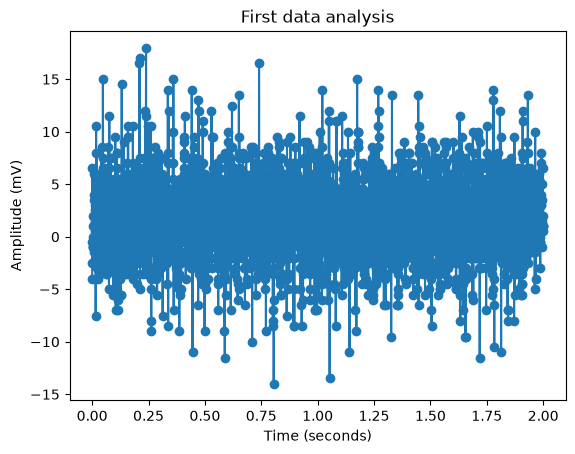

In [12]:
plt.plot(time, emg, marker="o")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("First data analysis")
plt.show()

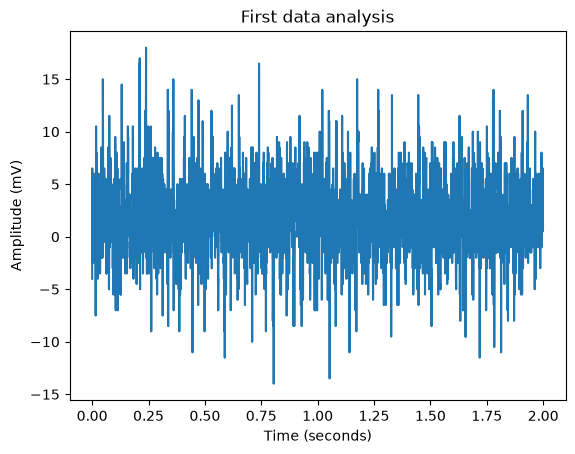

In [13]:
plt.plot(time, emg)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("First data analysis")
plt.show()

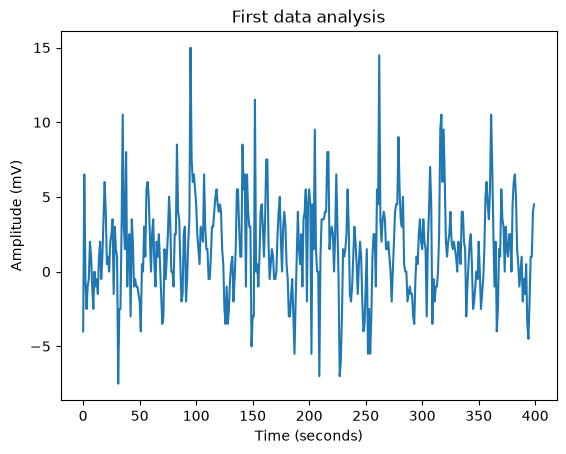

In [14]:

plt.plot(emg[time < 0.2])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("First data analysis")
plt.show()

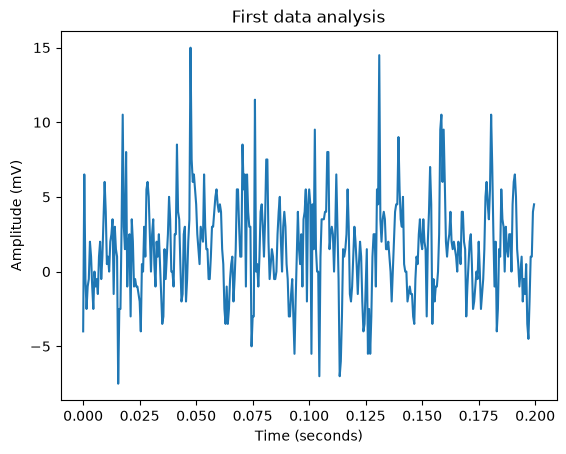

In [15]:
plt.plot(time[time < 0.2], emg[time < 0.2])

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("First data analysis")
plt.show()

In [16]:
emg_example = np.array([2, -4, 6, -2, 4])
mav = np.mean(emg_example)
print(mav)

1.2


In [17]:
mav = np.mean(np.abs(emg))
print(mav)

2.9799441572604946


In [18]:
rms = np.sqrt(np.mean(np.abs(emg ** 2)))
print(rms)

3.8392489818909983


Dataset and signal details

Source: PhysioNet surface EMG walking dataset

Record: S01

Selected channel: semg LT TIB.A (left tibialis anterior surface EMG)

Sampling rate: 2,000 Hz (2,000 samples per second)

Segment analyzed: First 2 seconds (4,000 samples)

Amplitude unit: Microvolts (μV), as specified in the dataset documentation

The signal was plotted over time to examine its fluctuations. Mean Absolute Value (MAV) was calculated to summarize its average absolute magnitude.

In [19]:
print(np.argmax(emg))
print(np.argmin(emg))

478
1610


In [20]:
peak_index = np.argmax(emg)
peak_time = time[peak_index]
peak_amplitude = emg[peak_index]

print(peak_time)
print(peak_amplitude)

0.239
17.99562516551596


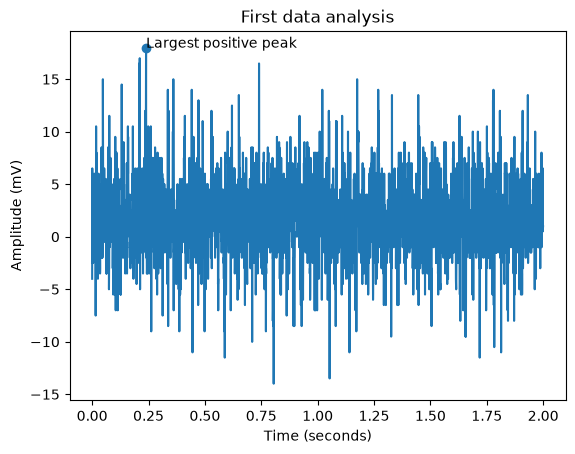

In [21]:
plt.plot(time, emg)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("First data analysis")
plt.scatter(peak_time, peak_amplitude)
plt.annotate("Largest positive peak", (peak_time, peak_amplitude))
plt.show()

In [22]:
mav = np.mean(np.abs(emg))
rms = np.sqrt(np.mean(emg ** 2))
print(mav)
print(rms)

2.9799441572604946
3.8392489818909983


High-pass filter: 10 Hz

Reduces slow variations below the cutoff, including some low-frequency movement artifacts.


Low-pass filter: 450 Hz

Reduces higher-frequency content above the cutoff.


Sampling rate: 2,000 Hz

The recording system takes 2,000 samples per second.

In [23]:
# Calculate the frequency components
spectrum = np.fft.rfft(emg)

# Find the frequency associated with each component
frequencies = np.fft.rfftfreq(len(emg), d=1/record.fs)

print(frequencies[:10])
print(spectrum[:10])

[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5]
[7099.45137324  +0.j           25.99026021-144.70695329j
   46.14474757 -89.22044498j  -58.8043847  +16.70051346j
   10.73565827 +97.73438285j -328.8982862  +41.58777669j
  137.70296851+102.60308752j  102.60945856 +24.4689051j
  136.11587536+176.62968188j  237.92087302 -84.22826684j]


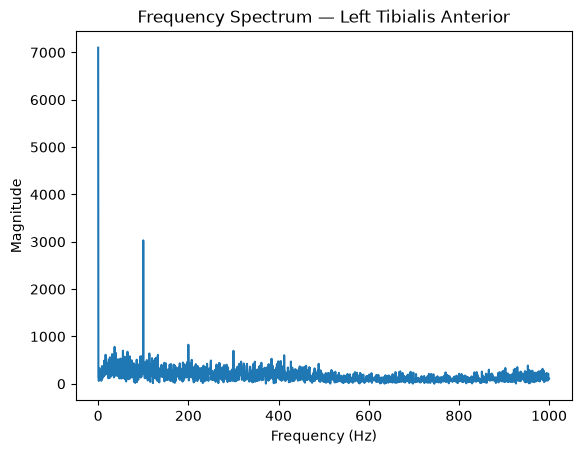

In [24]:
# Calculate the magnitude of each frequency component
magnitude = np.abs(spectrum)

plt.plot(frequencies, magnitude)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Spectrum — Left Tibialis Anterior")
plt.show()

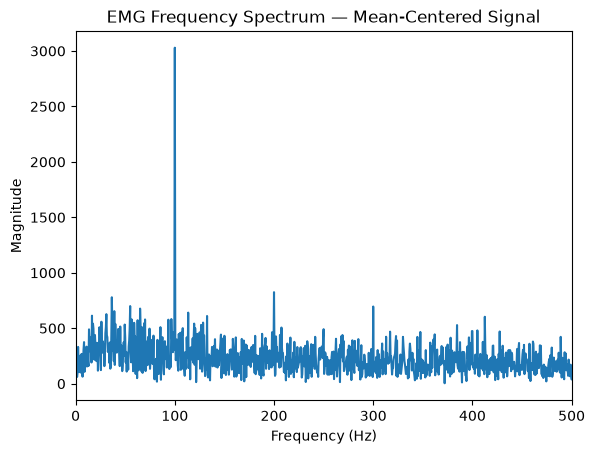

In [25]:
# Remove the signal's average value
emg_centered = emg - np.mean(emg)

# Calculate its frequency spectrum
spectrum_centered = np.fft.rfft(emg_centered)
frequencies = np.fft.rfftfreq(len(emg_centered), d=1/record.fs)

# Calculate the magnitude
magnitude_centered = np.abs(spectrum_centered)

# Plot frequencies up to 500 Hz
plt.plot(frequencies, magnitude_centered)
plt.xlim(0, 500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("EMG Frequency Spectrum — Mean-Centered Signal")
plt.show()

In [26]:
window_size = 10

moving_average = np.ones(window_size) / window_size

emg_smoothed = np.convolve(emg, moving_average, mode='same')

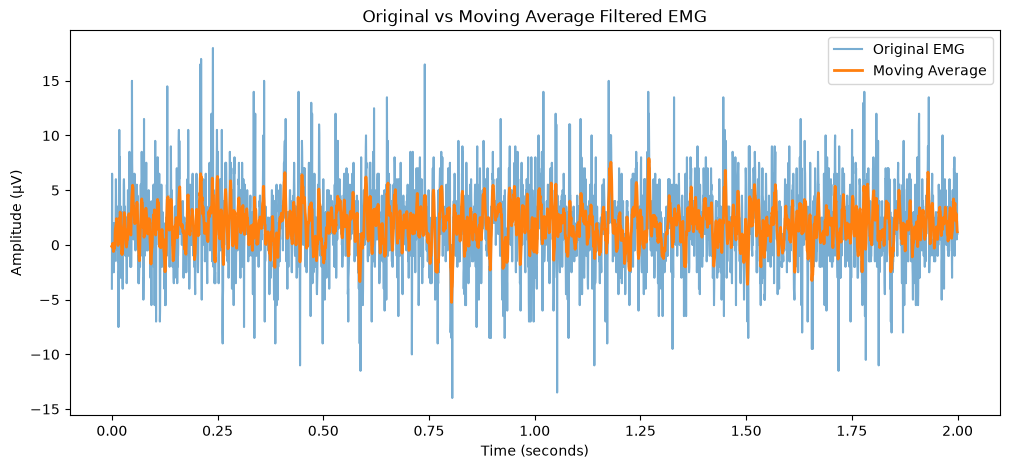

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(time, emg, label='Original EMG', alpha=0.6)
plt.plot(time, emg_smoothed, label='Moving Average', linewidth=2)

plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude (μV)')
plt.title('Original vs Moving Average Filtered EMG')
plt.legend()
plt.show()

In [28]:
mav_smoothed = np.mean(np.abs(emg_smoothed))
rms_smoothed = np.sqrt(np.mean(emg_smoothed ** 2))

print("Smoothed MAV:", mav_smoothed)
print("Smoothed RMS:", rms_smoothed)

Smoothed MAV: 2.0496203819743473
Smoothed RMS: 2.4841458137756365


In [29]:
spectrum_smoothed = np.fft.rfft(emg_smoothed)

magnitude_smoothed = np.abs(spectrum_smoothed)

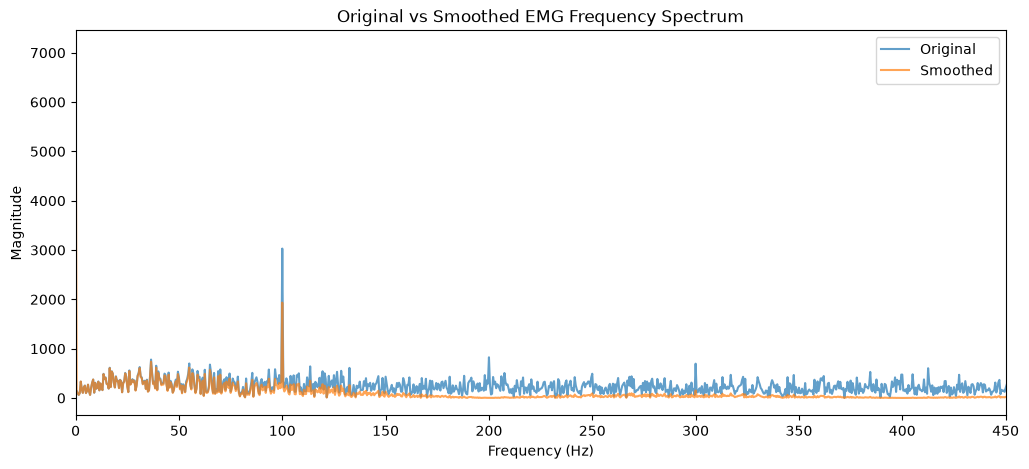

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(frequencies, magnitude_centered,
         label="Original", alpha=0.7)

plt.plot(frequencies, magnitude_smoothed,
         label="Smoothed", alpha=0.7)

plt.xlim(0, 450)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Original vs Smoothed EMG Frequency Spectrum")
plt.legend()
plt.show()

In [31]:
emg_smoothed_centered = emg_smoothed - np.mean(emg_smoothed)

spectrum_smoothed_centered = np.fft.rfft(
    emg_smoothed_centered
)

magnitude_smoothed_centered = np.abs(
    spectrum_smoothed_centered
)

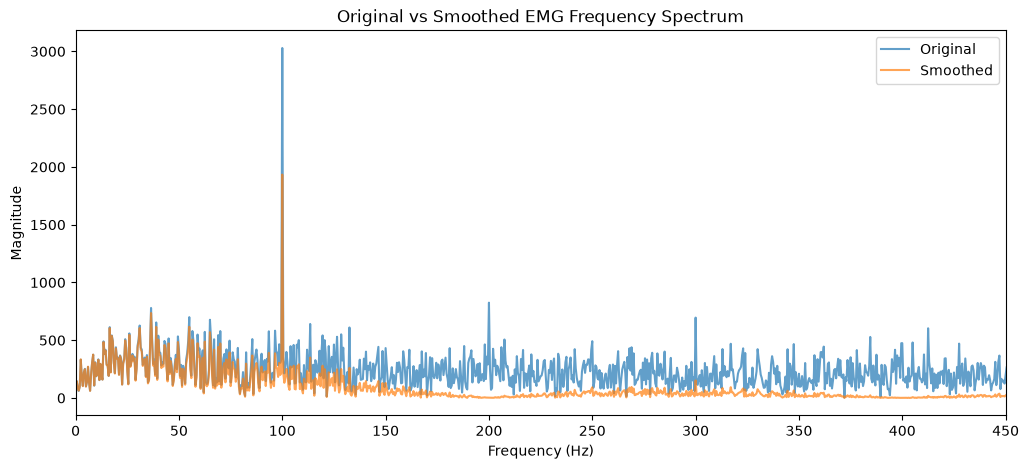

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(frequencies, magnitude_centered,
         label="Original", alpha=0.7)

plt.plot(frequencies, magnitude_smoothed_centered,
         label="Smoothed", alpha=0.7)

plt.xlim(0, 450)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Original vs Smoothed EMG Frequency Spectrum")
plt.legend()
plt.show()